In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm, to_rgb
from matplotlib.lines import Line2D

import json

### Read AIA results

In [2]:
aia_df = pd.read_csv("../vine_evaluation/inference/reg_coeff.csv", index_col=0)

In [3]:
aia_df.head()

,genModel,truncLvl,sa,tid,gameID,synDataID,coefficient,value
0,CVCDA,1,x1,ID84,0,0,x2,0.002558
1,CVCDA,1,x1,ID84,0,0,x3,-0.031352
2,CVCDA,1,x1,ID84,0,0,x4,0.009242
3,CVCDA,1,x1,ID84,0,0,x5,0.034634
4,CVCDA,1,x1,ID84,0,0,x6,-0.055396


In [4]:
aia_df.genModel.unique()

array(['CVCDA', 'IMRV(0.25)', 'IMRV(0.5)', 'IMRV(0.75)',
       'CvineSensitive(5)', 'Cvine', 'CVCDASensitive'], dtype=object)

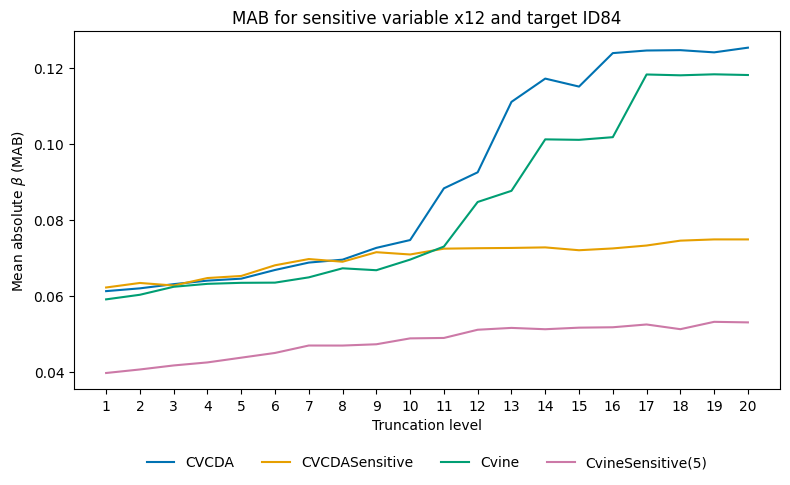

In [5]:
maxTrunc = aia_df.truncLvl.max()
sa = "x12"
tid = "ID84"

fig, ax = plt.subplots(figsize=(8, 5))

gmList = ["CVCDA", "CVCDASensitive", "Cvine", "CvineSensitive(5)"]
cols = ["#0072B2", "#E69F00", "#009E73", "#CC79A7"]

for gm, col in zip(gmList, cols):
    sub = aia_df.loc[(aia_df["genModel"] == gm) & (aia_df["tid"] == tid) & (aia_df["sa"] == sa),:]

    sub.groupby("truncLvl")["value"].apply(lambda x: x.abs().mean()).plot(ax=ax, label=gm, color=col,)

ax.set_xticks(sub.truncLvl.unique(), sub.truncLvl.unique())
ax.set_xlabel("Truncation level")
ax.set_ylabel(r"Mean absolute $\beta$ (MAB)")
ax.set_title(f"MAB for sensitive variable {sa} and target {tid}")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=4, frameon=False)

fig.tight_layout()
plt.show()

### Read utility evaluation results

In [6]:
with open("../vine_evaluation/utility/utility_metrics_simulated_data_tvinesynth.json") as f:
    obj = json.load(f)

In [7]:
obj.keys()

dict_keys(['Raw', 'CVCDA', 'IMRV(0.25)', 'IMRV(0.5)', 'IMRV(0.75)', 'CvineSensitive(5)', 'Cvine', 'CVCDASensitive'])

In [8]:
utility_df = pd.DataFrame(None, columns=["genModel", "trunc_lvl", "AUC-ROC", "Accuracy"])

In [9]:
raw_df = pd.DataFrame(obj["Raw"])
raw_df["genModel"] = "Raw"
raw_df["trunc_lvl"] = np.nan

utility_df = pd.concat([utility_df, raw_df[["genModel", "trunc_lvl", "AUC-ROC", "Accuracy"]]], ignore_index=True)

/tmp/ipykernel_2930288/665015034.py:5: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  utility_df = pd.concat([utility_df, raw_df[["genModel", "trunc_lvl", "AUC-ROC", "Accuracy"]]], ignore_index=True)


In [10]:
rows = []
for model in ['CVCDA', 'IMRV(0.25)', 'IMRV(0.5)', 'IMRV(0.75)', 'CvineSensitive(5)', 'Cvine', 'CVCDASensitive']:
    for trunc_lvl, metrics in obj[model].items():
        n = len(metrics["Accuracy"])
        rows.append(pd.DataFrame({
            "genModel": [model] * n,
            "trunc_lvl": [int(trunc_lvl)] * n,
            "AUC-ROC": metrics["AUC-ROC"],
            "Accuracy": metrics["Accuracy"],
        }))

    model_df = pd.concat(rows, ignore_index=True)
    
    utility_df = pd.concat([utility_df, model_df], ignore_index=True)

In [11]:
utility_df.genModel.unique()

array(['Raw', 'CVCDA', 'IMRV(0.25)', 'IMRV(0.5)', 'IMRV(0.75)',
       'CvineSensitive(5)', 'Cvine', 'CVCDASensitive'], dtype=object)

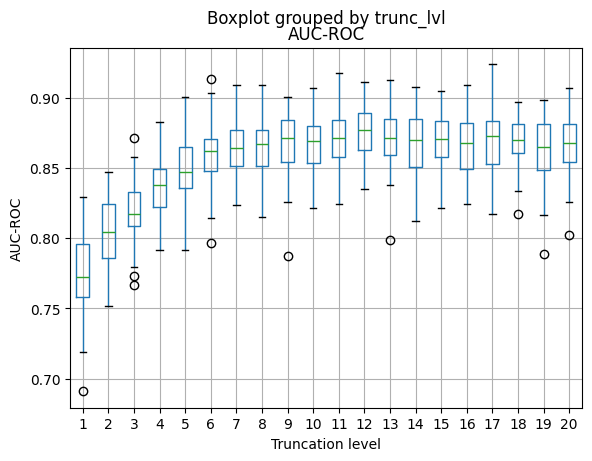

In [12]:
utility_df.loc[utility_df["genModel"]=="CVCDASensitive",].boxplot(column="AUC-ROC", by="trunc_lvl", 
                                     xlabel="Truncation level", ylabel="AUC-ROC")
plt.show()

## Privacy-utility plots

In [13]:
## Perhaps one plot per model, and use same x and y axes ...

In [14]:
gmList

['CVCDA', 'CVCDASensitive', 'Cvine', 'CvineSensitive(5)']

In [15]:
aia = aia_df.loc[(aia_df["tid"] == tid) & (aia_df["sa"]==sa), ["genModel", "truncLvl", "value"]]

In [16]:
tmp_aia = aia.groupby(["genModel", "truncLvl"]).value.apply(lambda x: x.abs().mean()).to_frame()

In [17]:
tmp_aia

value
genModel   truncLvl          
CVCDA      1         0.061257
           2         0.061987
           3         0.063092
           4         0.064019
           5         0.064536
...                       ...
IMRV(0.75) 16        0.059583
           17        0.059106
           18        0.059679
           19        0.059118
           20        0.059081

[140 rows x 1 columns]

In [18]:
utility_df.rename(columns={"trunc_lvl":"truncLvl"}, inplace=True)
tmp_utility = utility_df.loc[utility_df["genModel"]!="Raw",].groupby(["genModel", "truncLvl"])["AUC-ROC"].mean().to_frame()

In [19]:
tmp_utility

AUC-ROC
genModel   truncLvl          
CVCDA      1         0.675721
           2         0.679912
           3         0.675346
           4         0.680695
           5         0.676700
...                       ...
IMRV(0.75) 16        0.681823
           17        0.677184
           18        0.677793
           19        0.677780
           20        0.680696

[140 rows x 1 columns]

In [20]:
utility_df.genModel.unique()

array(['Raw', 'CVCDA', 'IMRV(0.25)', 'IMRV(0.5)', 'IMRV(0.75)',
       'CvineSensitive(5)', 'Cvine', 'CVCDASensitive'], dtype=object)

In [21]:
privacy_utility_df = pd.concat([tmp_aia, tmp_utility], axis=1)
privacy_utility_df.rename(columns={"value":"mab", "AUC-ROC": "auc"}, inplace=True)
privacy_utility_df

mab       auc
genModel   truncLvl                    
CVCDA      1         0.061257  0.675721
           2         0.061987  0.679912
           3         0.063092  0.675346
           4         0.064019  0.680695
           5         0.064536  0.676700
...                       ...       ...
IMRV(0.75) 16        0.059583  0.681823
           17        0.059106  0.677184
           18        0.059679  0.677793
           19        0.059118  0.677780
           20        0.059081  0.680696

[140 rows x 2 columns]

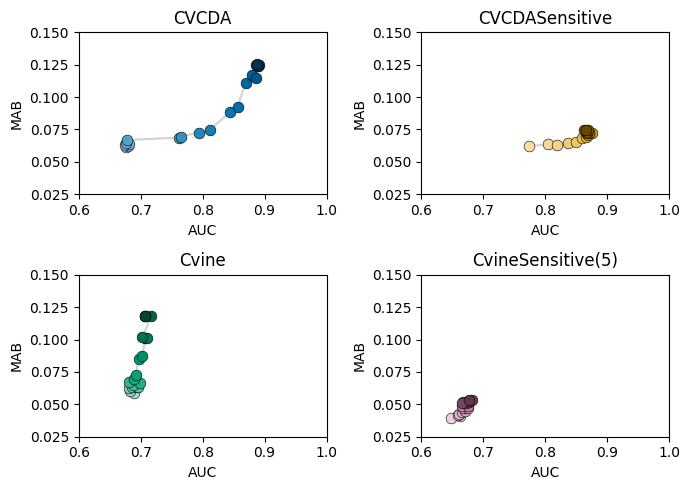

In [22]:


fig, axs = plt.subplots(2, 2, figsize=(7, 5))

ind = 0
for i in [0,1]:
    for j in [0,1]:
        ax = axs[i][j]
        gm = gmList[ind]
        col = cols[ind]

        plot_df = privacy_utility_df.xs(gm, level="genModel").reset_index().sort_values("truncLvl")

        base = np.array(to_rgb(col))
        levels = np.sort(plot_df["truncLvl"].unique())
        n = len(levels)

        def tint_shade(c, f):
            return c + (1 - c) * (-f) if f < 0 else c * (1 - f)

        colors = [tint_shade(base, f) for f in np.linspace(-0.65, 0.55, n)]
        cmap = ListedColormap(colors)
        norm = BoundaryNorm(np.arange(-0.5, n + 0.5), n)

        level_idx = np.searchsorted(levels, plot_df["truncLvl"])

        ax.plot(plot_df["auc"], plot_df["mab"], color="gray", alpha=0.35, zorder=1)

        for lvl, col in zip(levels, colors):
            d = plot_df[plot_df["truncLvl"] == lvl]
            ax.scatter(d["auc"], d["mab"], color=col, s=60,
                    edgecolor="black", linewidth=0.4, zorder=2, label=str(lvl))

        # ax.legend(title="Truncation level", frameon=False,
        #         loc="center left", bbox_to_anchor=(1.01, 0.5))
        ax.set(ylabel="MAB", xlabel="AUC", title=gm)
        ax.set_xlim(0.6, 1)
        ax.set_ylim(0.025, 0.15)
        
        ind += 1
        
plt.tight_layout()
plt.show()

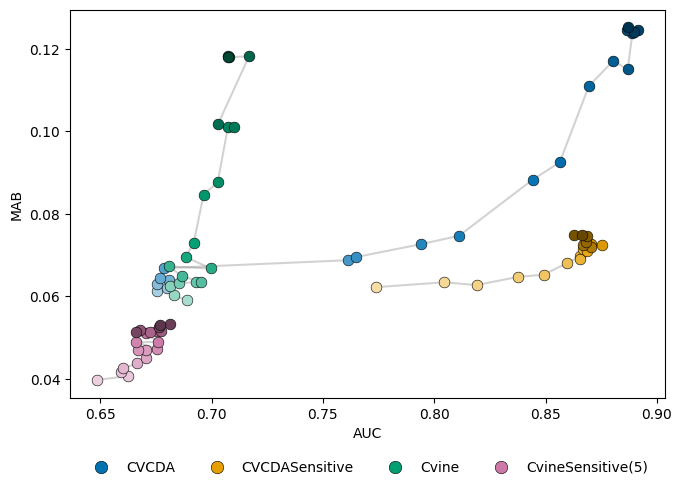

In [23]:
def tint_shade(c, f):
    return c + (1 - c) * (-f) if f < 0 else c * (1 - f)

fig, ax = plt.subplots(figsize=(7, 5))

for gm, col in zip(gmList, cols):
    plot_df = (privacy_utility_df.xs(gm, level="genModel")
               .reset_index()
               .sort_values("truncLvl"))

    base = np.array(to_rgb(col))
    levels = np.sort(plot_df["truncLvl"].unique())
    colors = [tint_shade(base, f) for f in np.linspace(-0.65, 0.55, len(levels))]

    ax.plot(plot_df["auc"], plot_df["mab"], color="gray", alpha=0.35, zorder=1)

    for lvl, c in zip(levels, colors):
        d = plot_df[plot_df["truncLvl"] == lvl]
        ax.scatter(d["auc"], d["mab"], color=c, s=60,
                   edgecolor="black", linewidth=0.4, zorder=2)

# Single legend below the x-axis, no border
model_handles = [
    Line2D([0], [0], marker="o", color="none", markerfacecolor=col,
           markeredgecolor="black", markeredgewidth=0.4,markersize=9, label=gm) for gm, col in zip(gmList, cols)]
ax.legend(handles=model_handles, frameon=False,
          loc="upper center", bbox_to_anchor=(0.5, -0.13),
          ncol=len(gmList))

ax.set(xlabel="AUC", ylabel="MAB")

plt.tight_layout()
plt.show()